# Program 35: Customer Transaction Spends (K-Means)

**Scenario / Problem Statement**

Use K-Means to segment retail customers using total amount spent and visit frequency.

Run the cells from top to bottom in Google Colab.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


## 2. Load data and perform the analysis

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q35_Retail_Store_KMeans.csv
Dataset shape: (70, 4)
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
Cluster centers:


,Customer_ID,Store_Branch,Total_Amount_Spent,Visit_Frequency
0,RT-001,Central,$163.34,3
1,RT-002,South,$89.31,1
2,RT-003,North,$55.17,2
3,RT-004,South,$149.24,3
4,RT-005,Central,$124.74,4


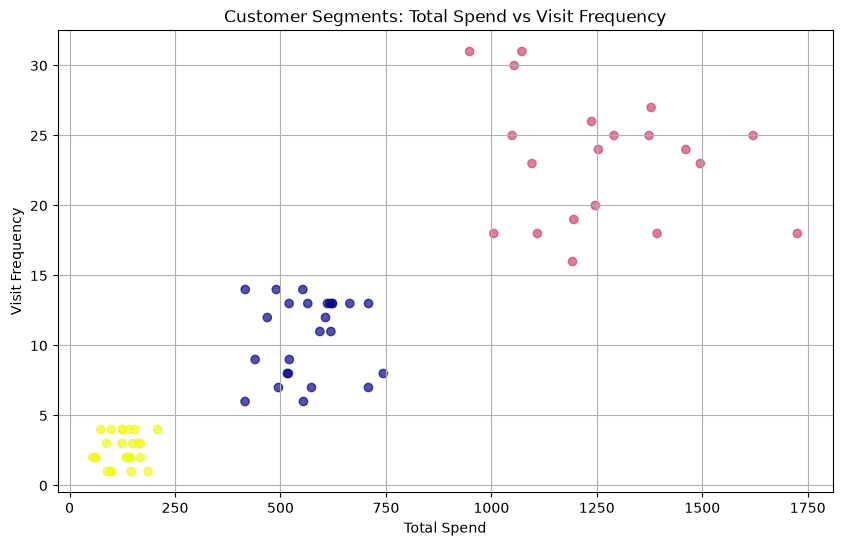

,Total_Amount_Spent,Visit_Frequency
0,566.7340,10.68
1,1259.9770,23.30
2,125.7452,2.56


In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q35_Retail_Store_KMeans.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q35_Retail_Store_KMeans.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

df_raw["Total_Amount_Spent"] = pd.to_numeric(df_raw["Total_Amount_Spent"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False), errors="coerce")
data = df_raw.dropna(subset=["Total_Amount_Spent", "Visit_Frequency"]).copy()
features = ["Total_Amount_Spent", "Visit_Frequency"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[features])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data["Segment"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(10, 6))
plt.scatter(data["Total_Amount_Spent"], data["Visit_Frequency"], c=data["Segment"], cmap="plasma", alpha=0.7)
plt.title("Customer Segments: Total Spend vs Visit Frequency")
plt.xlabel("Total Spend")
plt.ylabel("Visit Frequency")
plt.grid(True)
plt.show()

print("Cluster centers:")
display(pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features))

## 3. Result

The output above displays the required analysis, model results, or visualization.